In [1]:
from square import *
import qibo
from qibo import Circuit, gates, set_backend
import time


set_backend("qibojit", platform="cuda")

[Qibo 0.3.5|INFO|2026-10-14 09:17:16]: Using qibojit (numba) backend on /CPU:0


# Ripple carry adder

In [2]:
n_qubits = list(range(2,20))
cnots = []
toffolis = []
depths = []
total = []
xs = []
for m in n_qubits:
    sq, allocs = Square(m, method='ripple_input_carry', input_swaps = False) # Select method 
    
    stats={
        'input_qubits' : m,
        'total_qubits' : sq.nqubits,
        'total_gates' : sq.ngates,
        'depth' : sq.depth,
    }
    common_gates = sq.gate_names.most_common()
    for g, n in common_gates:
        stats = stats | {g : n}
    print('===================')
    for stat in stats.keys():
        print(f'{stat} : {stats[stat]}')
    cnots.append(stats['cx'])
    toffolis.append(stats['ccx'])
    depths.append(stats['depth'])
    total.append(stats['total_gates'])
    xs.append(stats['x'])


input_qubits : 2
total_qubits : 9
total_gates : 90
depth : 58
cx : 48
x : 25
ccx : 17
input_qubits : 3
total_qubits : 13
total_gates : 187
depth : 112
cx : 103
x : 51
ccx : 33
input_qubits : 4
total_qubits : 17
total_gates : 310
depth : 177
cx : 172
x : 85
ccx : 53
input_qubits : 5
total_qubits : 21
total_gates : 459
depth : 255
cx : 255
x : 127
ccx : 77
input_qubits : 6
total_qubits : 25
total_gates : 634
depth : 345
cx : 352
x : 177
ccx : 105
input_qubits : 7
total_qubits : 29
total_gates : 835
depth : 447
cx : 463
x : 235
ccx : 137
input_qubits : 8
total_qubits : 33
total_gates : 1062
depth : 561
cx : 588
x : 301
ccx : 173
input_qubits : 9
total_qubits : 37
total_gates : 1315
depth : 687
cx : 727
x : 375
ccx : 213
input_qubits : 10
total_qubits : 41
total_gates : 1594
depth : 825
cx : 880
x : 457
ccx : 257
input_qubits : 11
total_qubits : 45
total_gates : 1899
depth : 975
cx : 1047
x : 547
ccx : 305
input_qubits : 12
total_qubits : 49
total_gates : 2230
depth : 1137
cx : 1228
x : 64

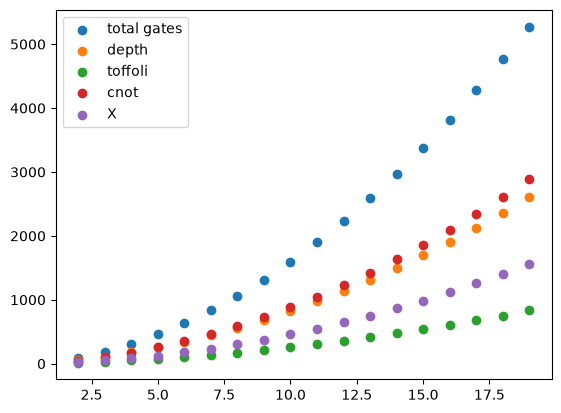

In [3]:
import matplotlib.pyplot as plt

plt.scatter(n_qubits, total, label = 'total gates')
plt.scatter(n_qubits, depths, label = 'depth')
plt.scatter(n_qubits, toffolis, label = 'toffoli')
plt.scatter(n_qubits, cnots, label = 'cnot')
plt.scatter(n_qubits, xs, label = 'X')

plt.legend()


In [4]:
from scipy.optimize import curve_fit

def poly(x, a0, a1, a2):
    y = a0 + a1*x + a2*x**2
    return y

In [5]:
data = {'total_gates': total,
        'depth': depths,
        'toffoli': toffolis,
        'cnot': cnots,
        'x': xs
        }

for stat in data.keys():
        param, _ = curve_fit(poly, n_qubits[1:], data[stat][1:])
        print(f'======{stat}======')
        for i in range(len(param)):
                print(f'a{i} : {param[i]}')

======total_gates======
a0 : -25.999999999999993
a1 : 32.0
a2 : 13.0
======depth======
a0 : -14.22497411607018
a1 : 23.86687304917185
a2 : 6.005159959367385
======toffoli======
a0 : -3.0000000000000275
a1 : 6.000000000000008
a2 : 1.9999999999999996
======cnot======
a0 : -20.00000000000006
a1 : 20.000000000000018
a2 : 6.999999999999999
======x======
a0 : -3.000000000000035
a1 : 6.000000000000011
a2 : 3.9999999999999996


# Approx. QFT scaling

In [6]:
import numpy as np
from tqdm import tqdm

m_max = 14
m_range = list(range(2, m_max))

stats = ['total_gates', 'depth', 'toffoli', 'cnot', 'x', 'h', 'cu1']
values = {key : np.zeros((len(m_range), 2*m_max)) for key in stats}


for i_m in tqdm(range(len(m_range))):
    i_d = 0
    for delta in range(1, 2*m_range[i_m]+1):
        sq, allocs = Square(i_m+2, method='aqft', delta = delta, parallel = False,input_swaps = False)

        values['total_gates'][i_m, i_d] = sq.ngates
        values['depth'][i_m, i_d] = sq.depth
        values['toffoli'][i_m, i_d] = sq.gate_names['ccx']
        values['cnot'][i_m, i_d] = sq.gate_names['cx']
        values['x'][i_m, i_d] = sq.gate_names['x']
        values['h'][i_m, i_d] = sq.gate_names['h']
        values['cu1'][i_m, i_d] = sq.gate_names['cu1']
        i_d += 1








  0%|          | 0/12 [00:00<?, ?it/s]

100%|██████████| 12/12 [00:13<00:00,  1.12s/it]


In [7]:
from scipy.optimize import curve_fit

def poly(x, a0, a1, a2):
    y = a0 + a1*x + a2*x**2
    return y

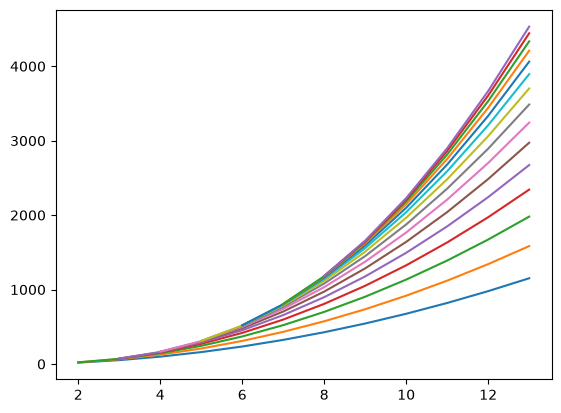

In [8]:
import matplotlib.pyplot as plt

stat = 'cu1'

b0 = np.zeros(2*m_max); b1 = np.zeros(2*m_max); b2 = np.zeros(2*m_max)

for i_d in range(1,2*(m_max-1)-10):
    delta = i_d + 1
    if delta <=4:
        min_m = 2
    else :
        min_m = np.ceil(delta/2)
    #print(min_m)
    min_i_m = m_range.index(int(min_m))
    param, _ = curve_fit(poly, m_range[min_i_m:], values[stat][min_i_m:,i_d])
    b0[i_d] = param[0]
    b1[i_d] = param[1]
    b2[i_d] = param[2]
    plt.plot(m_range[min_i_m:], values[stat][min_i_m:,i_d], label = f'd={delta}')

#plt.legend()
    

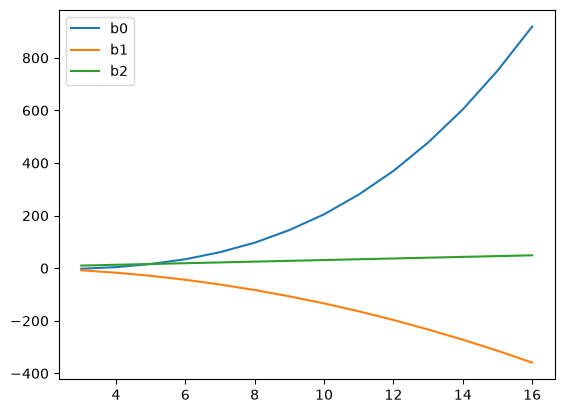

In [9]:
deltas = [s+1 for s in range(0,2*(m_max))]
smax = 16
smin = 2
deltas = deltas[smin:smax]
plt.plot(deltas, b0[smin:smax], label = 'b0') 
plt.plot(deltas, b1[smin:smax], label = 'b1') 
plt.plot(deltas, b2[smin:smax], label = 'b2') 
plt.legend()

In [10]:
print(b0[smin:smax])
print(b1[smin:smax])
print(b2[smin:smax])
deltas


[ -2.   4.  16.  34.  61.  97. 145. 205. 280. 370. 478. 604. 751. 919.]
[  -8.  -17.  -29.  -44.  -62.  -83. -107. -134. -164. -197. -233. -272.
 -314. -359.]
[10. 13. 16. 19. 22. 25. 28. 31. 34. 37. 40. 43. 46. 49.]


[3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

In [11]:
param, _ = curve_fit(poly, deltas, b2[smin:smax])
print(param)

[ 1.00000000e+00  3.00000000e+00 -1.33226765e-15]


# Time elapsed by m (ran in colab)

Exhaustive verification of the primitive for the different sub/add subroutines. For each input length $m$, the circuit is built and executed for all $2^m$ possible inputs. The wallclock time of 1 shot is averaged over all inputs and its mean and std. is stored; then, the result is verified repeating the measurement for ``nshots``, computing the average error over all inputs.
The result is the scaling of both the average simulation time and error over the ize of the length of the input integer.

qibojit GPU T4

In [12]:
"""Benchmark de Square(m) con distintos sumadores (qibojit + GPU).

Diferencias respecto a la version anterior:
  - Tiempo y error se miden por separado.
  - Tiempo: SIN puertas de medida, con warm-up, repeticiones y sincronizacion de GPU.
  - Error: fidelidad exacta P(R = x^2) calculada desde el estado (sin shots).
  - El circuito Square se construye una sola vez por (m, metodo).
  - Se guarda tambien el conteo de puertas por tipo (para el modelo de coste).
"""
import json
import random
import time
from collections import Counter

import numpy as np
from qibo import set_backend

from square import Square, initialize_square

# ---------------------------------------------------------------- config
PRECISION = "double"             # "single" -> ~2x en la T4 (FP64 es lento); "double" = por defecto

set_backend("qibojit", platform="cuda")


def set_prec(p):
    """La API de precision cambia entre versiones de qibo: probamos varias rutas."""
    if p == "double":
        return                   # ya es la precision por defecto
    try:
        from qibo import set_precision
        return set_precision(p)
    except ImportError:
        pass
    try:
        from qibo.backends import set_precision
        return set_precision(p)
    except ImportError:
        pass
    from qibo import get_backend
    get_backend().set_dtype("complex64")


set_prec(PRECISION)

try:
    import cupy as cp
    def sync():
        cp.cuda.Device().synchronize()
except ImportError:              # backend en CPU
    cp = None
    def sync():
        pass

M_VALUES = range(2, 7)
WARMUP = 1
REPEATS = 5
MAX_X_FIDELITY = None              # x usados para el error cuando 2**m es mayor (None = todos)
SEED = 0

CONFIGS = {
    "ripple_ic":          dict(method="ripple_input_carry"),
    "ripple_no_ic":       dict(method="ripple_no_input_carry"),
    "qft":                dict(method="aqft", parallel=False),               # delta se fija a 2*m
    "qft_parallel":       dict(method="aqft", parallel=True),
    "aqft_d4":            dict(method="aqft", parallel=False, delta=4),
    "aqft_parallel_d4":   dict(method="aqft", parallel=True, delta=4),
}


# ---------------------------------------------------------------- helpers
def build(m, kw):
    """Circuito Square (sin init ni medidas) y allocs. delta por defecto = 2*m (QFT exacta)."""
    kw = dict(kw)
    if kw.get("method") == "aqft":
        kw.setdefault("delta", 2 * m)
    return Square(m, input_swaps=False, **kw)


def full_circuit(sq, m, x, allocs):
    n = 2 * m
    circ = initialize_square(x, m, allocs=allocs, direct=True)
    circ.add(sq.on_qubits(*range(2 * n + 1)))
    return circ                  # sin gates.M


def get_state(res):
    try:
        return res.state(numpy=False)    # se queda en la GPU si la version lo soporta
    except TypeError:
        return res.state()


def prob_correct(res, m, R):
    """P(R = x^2 | x) sumando sobre el resto de registros. Qubit 0 = bit mas significativo."""
    n = 2 * m
    assert list(R) == list(range(n)), "esta funcion asume R = range(n) (allocs por defecto)"
    psi = get_state(res)
    xp = cp.get_array_module(psi) if cp is not None else np
    psi = psi.reshape(2 ** n, -1)
    return psi, xp


def fidelity(res, m, R, x):
    psi, xp = prob_correct(res, m, R)
    n = 2 * m
    x2 = x * x
    idx = sum(((x2 >> q) & 1) << (n - 1 - q) for q in range(n))
    return float(xp.sum(xp.abs(psi[idx]) ** 2))


def time_circuit(circ):
    for _ in range(WARMUP):
        circ()
    sync()
    ts = []
    for _ in range(REPEATS):
        sync()
        t0 = time.perf_counter()
        circ()
        sync()
        ts.append(time.perf_counter() - t0)
    return float(np.mean(ts)), float(np.std(ts))


# ---------------------------------------------------------------- main
def main():
    rng = random.Random(SEED)
    results = {name: {"m": [], "t": [], "t_sd": [], "err": [], "gates": [], "by_type": []}
               for name in CONFIGS}

    for m in M_VALUES:
        xs = list(range(2 ** m))
        if MAX_X_FIDELITY is not None and len(xs) > MAX_X_FIDELITY:
            xs = rng.sample(xs, MAX_X_FIDELITY)

        for name, kw in CONFIGS.items():
            sq, allocs = build(m, kw)
            R = allocs[0]

            # --- tiempo: una sola x (el conteo de puertas no depende de x)
            x_t = 2 ** m - 1
            circ_t = full_circuit(sq, m, x_t, allocs)
            t, t_sd = time_circuit(circ_t)

            # --- error: fidelidad exacta media sobre las x elegidas
            fids = []
            for x in xs:
                res = full_circuit(sq, m, x, allocs)()
                fids.append(fidelity(res, m, R, x))
            err = 1.0 - float(np.mean(fids))

            by_type = Counter(type(g).__name__ for g in circ_t.queue)
            r = results[name]
            r["m"].append(m); r["t"].append(t); r["t_sd"].append(t_sd); r["err"].append(err)
            r["gates"].append(len(circ_t.queue)); r["by_type"].append(dict(by_type))
            print(f"m={m} {name:17s} t={t:.4f}±{t_sd:.4f} s  gates={len(circ_t.queue):5d}  "
                  f"1-F={err:.2e}", flush=True)

    with open("benchmark_square_results.json", "w") as f:
        json.dump(results, f, indent=1)
    return results


if __name__ == "__main__":
    results = main()

[Qibo 0.3.5|INFO|2026-10-14 09:17:32]: Using qibojit (numba) backend on /CPU:0


m=2 ripple_ic         t=0.0015±0.0009 s  gates=   92  1-F=0.00e+00
m=2 ripple_no_ic      t=0.7930±0.1752 s  gates=   74  1-F=0.00e+00
m=2 qft               t=0.1613±0.2325 s  gates=   84  1-F=1.55e-15
m=2 qft_parallel      t=0.2184±0.1669 s  gates=   84  1-F=1.33e-15
m=2 aqft_d4           t=0.0251±0.0347 s  gates=   84  1-F=1.55e-15


SystemError: CPUDispatcher(<function multicontrol_apply_x_kernel at 0x780d55a9f560>) returned a result with an exception set

In [36]:
with open('/home/fredo/qibo_tests/qibo_benchmark/square-primitive/benchmark_square_results.json', 'r') as f:
    data = json.load(f)

In [37]:
data

{'ripple_ic': {'m': [2, 3, 4, 5, 6],
  't': [0.031129405819988278,
   0.02745175825998558,
   0.0468942253400246,
   0.16195927784001468,
   2.1588830991199983],
  't_sd': [0.010075537225769555,
   0.00475760036567027,
   0.007568997060236515,
   0.006402167988794058,
   0.003675647043206837],
  'err': [0.0, 0.0, 0.0, 0.0, 0.0],
  'gates': [92, 190, 314, 464, 640],
  'by_type': [{'X': 27, 'CNOT': 48, 'TOFFOLI': 17},
   {'X': 54, 'CNOT': 103, 'TOFFOLI': 33},
   {'X': 89, 'CNOT': 172, 'TOFFOLI': 53},
   {'X': 132, 'CNOT': 255, 'TOFFOLI': 77},
   {'X': 183, 'CNOT': 352, 'TOFFOLI': 105}]},
 'ripple_no_ic': {'m': [2, 3, 4, 5, 6],
  't': [0.023989043540013882,
   0.02313694476001274,
   0.03353963121999641,
   0.11049121373998333,
   1.3882691319199603],
  't_sd': [0.011022798093063836,
   0.005456544984657789,
   0.002913002637062159,
   0.004011922737112465,
   0.0041044119624830955],
  'err': [0.0, 0.0, 0.0, 0.0, 0.0],
  'gates': [74, 146, 236, 344, 470],
  'by_type': [{'X': 15, 'CNOT': 4

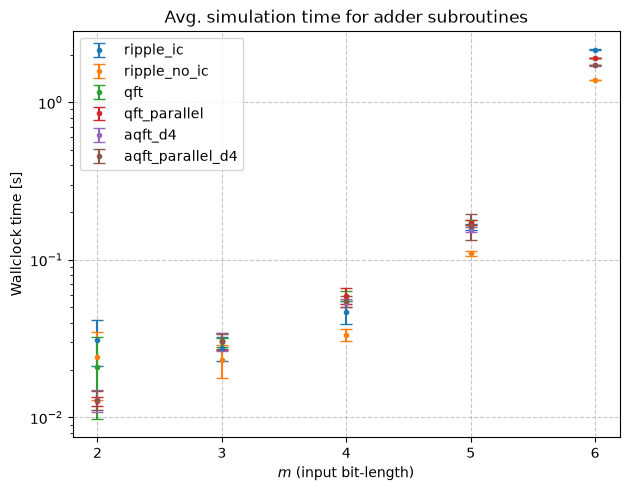

In [38]:
import matplotlib.pyplot as plt
mrange = data[list(data.keys())[0]]['m']
for met in data.keys():
    plt.errorbar(mrange, data[met]['t'], yerr=data[met]['t_sd'], markersize = 6, capsize=4, fmt=".", label = f'{met}')

plt.xticks(mrange)
plt.xlabel(r'$m$ (input bit-length)')
plt.ylabel(r'Wallclock time [s]')
plt.yscale('log')
plt.legend(frameon=True)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.title('Avg. simulation time for adder subroutines')
plt.show()

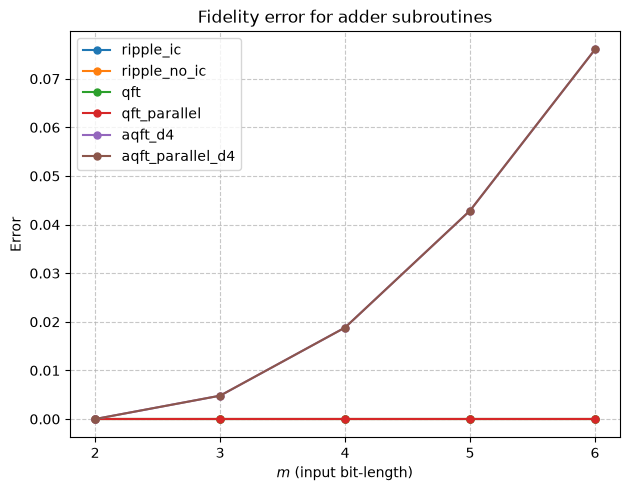

In [39]:
mrange = data[list(data.keys())[0]]['m']
for met in data.keys():
    plt.plot(mrange, data[met]['err'], marker="o", markersize = 5, label = f'{met}')

plt.xticks(mrange)
plt.xlabel(r'$m$ (input bit-length)')
plt.ylabel(r'Error')
#plt.yscale('log')
plt.legend(frameon=True)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.title('Fidelity error for adder subroutines')
plt.show()

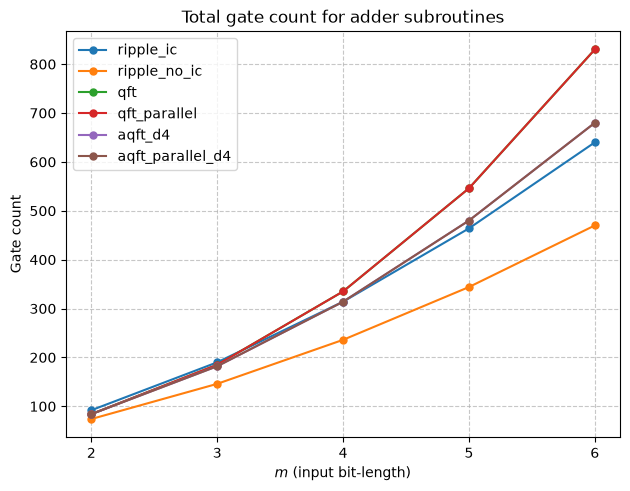

In [40]:
mrange = data[list(data.keys())[0]]['m']
for met in data.keys():
    plt.plot(mrange, data[met]['gates'], marker="o", markersize = 5,label = f'{met}')

plt.xticks(mrange)
plt.xlabel(r'$m$ (input bit-length)')
plt.ylabel(r'Gate count')
#plt.yscale('log')
plt.legend(frameon=True)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.title('Total gate count for adder subroutines')
plt.show()